# Assignment 2 — Question 2: Sampling and Bootstrap on the Diabetes Data

**Dataset:** `data/diabetes.csv`, 768 patients, 8 attributes, and a binary `Outcome` (1 = diabetes, 0 = no diabetes).
As the assignment instructs, the 768 rows are treated as the **population**.

| Part | Task |
|---|---|
| (a) | Random sample of 25 (seeded): mean and max `Glucose` vs population, with charts |
| (b) | 98th percentile of `BMI`, sample vs population, with charts |
| (c) | Bootstrap: 500 samples of 150 (with replacement); average mean, standard deviation, and 98th percentile of `BloodPressure` vs population, with charts and findings |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SEED = 42                 # fixed seed so every run gives the same results
np.random.seed(SEED)

POP_COLOR, SAMPLE_COLOR = "#4C72B0", "#DD8452"

population = pd.read_csv("../data/diabetes.csv")
print("Population shape:", population.shape)
population.head()

Population shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## (a) Random sample of 25: Glucose mean and maximum

`DataFrame.sample(n=25, random_state=SEED)` draws 25 patients **without replacement**. The seed makes the sample reproducible.

In [2]:
sample25 = population.sample(n=25, random_state=SEED)

glucose_cmp = pd.DataFrame({
    "Sample (n=25)":      [sample25["Glucose"].mean(), sample25["Glucose"].max()],
    "Population (N=768)": [population["Glucose"].mean(), population["Glucose"].max()],
}, index=["Mean Glucose", "Highest Glucose"])
glucose_cmp["Difference (sample - pop)"] = glucose_cmp.iloc[:, 0] - glucose_cmp.iloc[:, 1]
glucose_cmp["% difference"] = (glucose_cmp["Difference (sample - pop)"] / glucose_cmp.iloc[:, 1] * 100).round(2)
glucose_cmp.round(2)

,Sample (n=25),Population (N=768),Difference (sample - pop),% difference
Mean Glucose,116.64,120.89,-4.25,-3.52
Highest Glucose,183.00,199.00,-16.00,-8.04


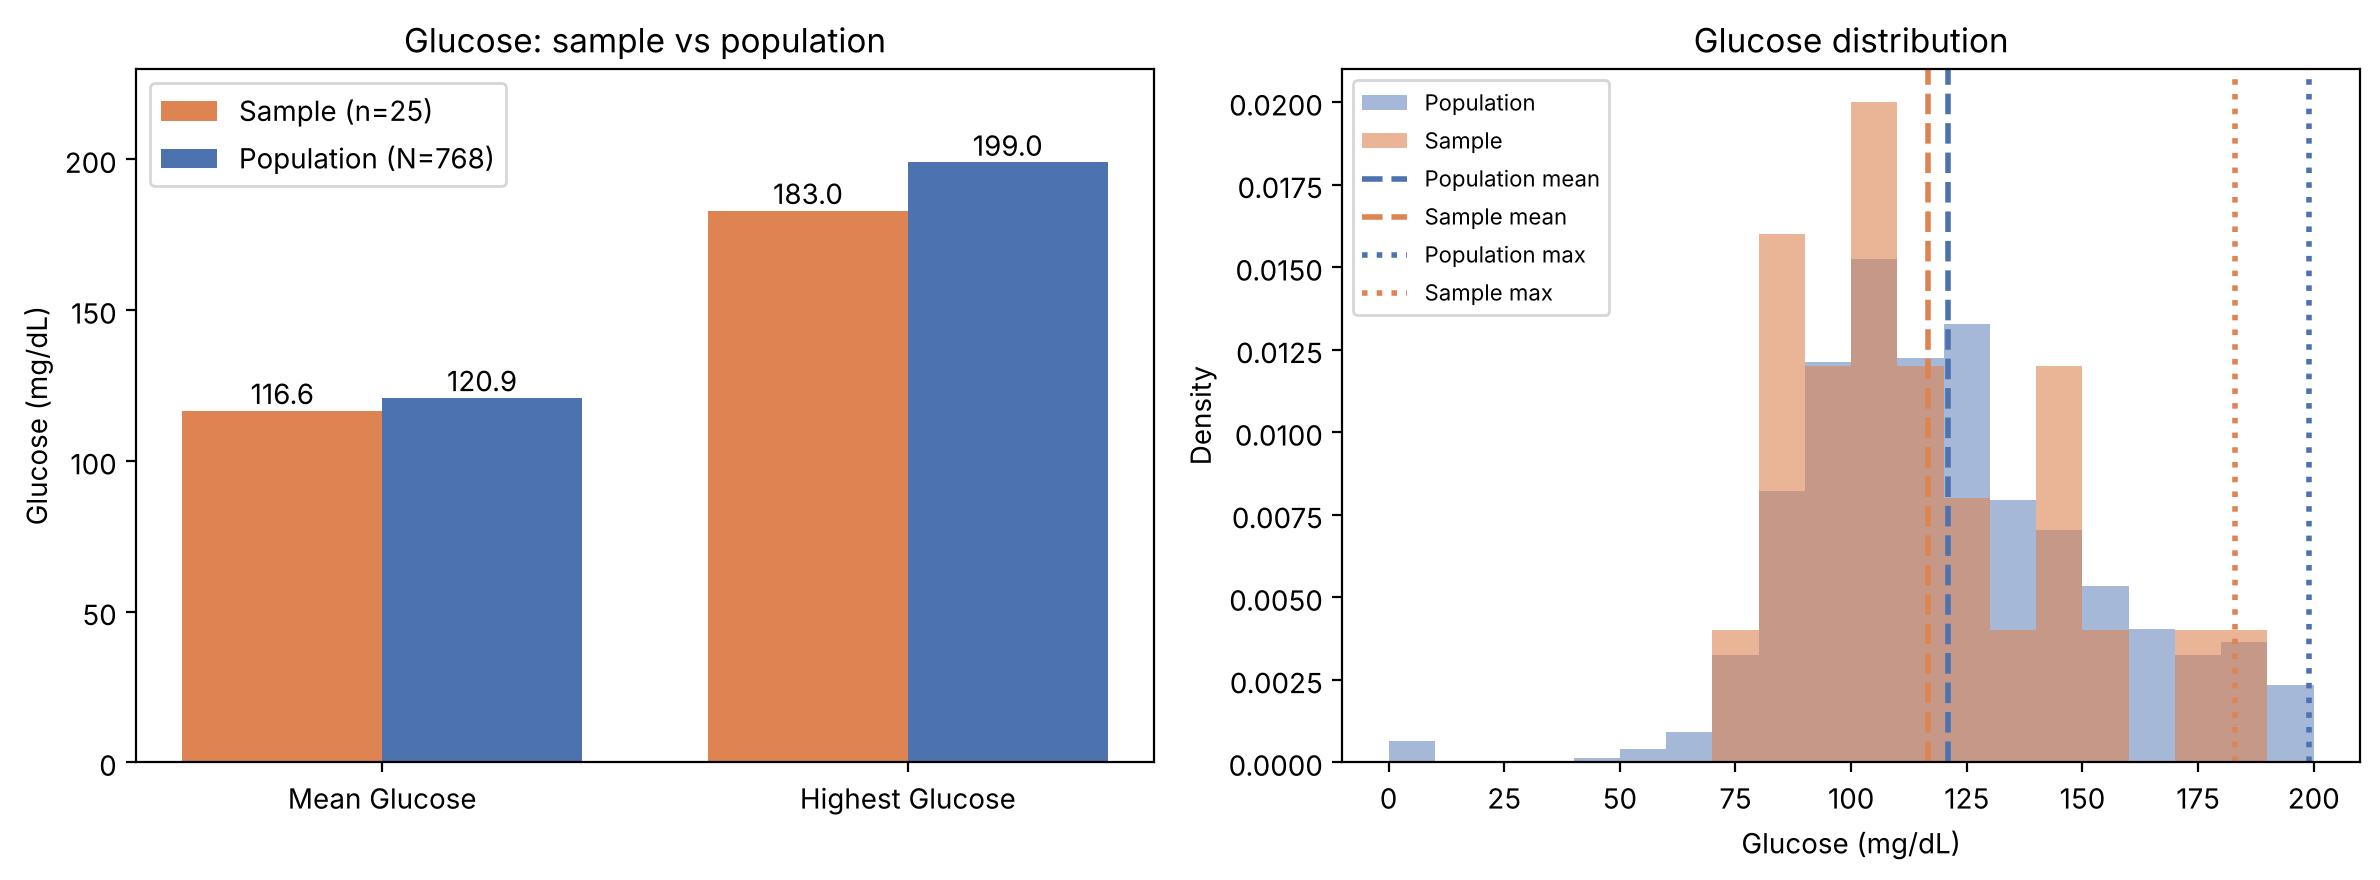

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Chart 1: side-by-side bars for mean and max
ax = axes[0]
x = np.arange(2)
w = 0.38
b1 = ax.bar(x - w/2, glucose_cmp["Sample (n=25)"], w, label="Sample (n=25)", color=SAMPLE_COLOR)
b2 = ax.bar(x + w/2, glucose_cmp["Population (N=768)"], w, label="Population (N=768)", color=POP_COLOR)
ax.bar_label(b1, fmt="%.1f"); ax.bar_label(b2, fmt="%.1f")
ax.set_xticks(x, glucose_cmp.index)
ax.set_ylabel("Glucose (mg/dL)")
ax.set_title("Glucose: sample vs population")
ax.legend(loc="upper left")
ax.set_ylim(0, 230)

# Chart 2: distributions with the mean and max marked
ax = axes[1]
bins = np.arange(0, 205, 10)
ax.hist(population["Glucose"], bins=bins, density=True, alpha=0.5, color=POP_COLOR, label="Population")
ax.hist(sample25["Glucose"], bins=bins, density=True, alpha=0.6, color=SAMPLE_COLOR, label="Sample")
ax.axvline(population["Glucose"].mean(), color=POP_COLOR, ls="--", lw=2, label="Population mean")
ax.axvline(sample25["Glucose"].mean(), color=SAMPLE_COLOR, ls="--", lw=2, label="Sample mean")
ax.axvline(population["Glucose"].max(), color=POP_COLOR, ls=":", lw=2, label="Population max")
ax.axvline(sample25["Glucose"].max(), color=SAMPLE_COLOR, ls=":", lw=2, label="Sample max")
ax.set_xlabel("Glucose (mg/dL)"); ax.set_ylabel("Density")
ax.set_title("Glucose distribution")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Observations (a)**

* The **sample mean** (116.6) is close to the **population mean** (120.9), about 3.5% lower. With only 25 observations some random error is expected, but the mean is a stable statistic, so the estimate is reasonable.
* The **sample maximum** (183) is well below the **population maximum** (199). The maximum comes from a single extreme value, and a sample of 25 out of 768 is unlikely to include it. The sample maximum can never be higher than the population maximum, so it is a **biased (low) estimator**: small samples tend to underestimate extremes.

## (b) 98th percentile of BMI: sample vs population

`np.percentile(x, 98)` gives the value below which 98% of the observations fall. The same 25-patient sample from part (a) is used.

In [4]:
bmi_p98_sample = np.percentile(sample25["BMI"], 98)
bmi_p98_pop = np.percentile(population["BMI"], 98)

bmi_cmp = pd.DataFrame({
    "98th percentile BMI": [bmi_p98_sample, bmi_p98_pop],
}, index=["Sample (n=25)", "Population (N=768)"]).round(2)
print(f"Difference (sample - population): {bmi_p98_sample - bmi_p98_pop:.2f} "
      f"({(bmi_p98_sample - bmi_p98_pop) / bmi_p98_pop:.1%})")
bmi_cmp

Difference (sample - population): -7.28 (-15.3%)


,98th percentile BMI
Sample (n=25),40.25
Population (N=768),47.53


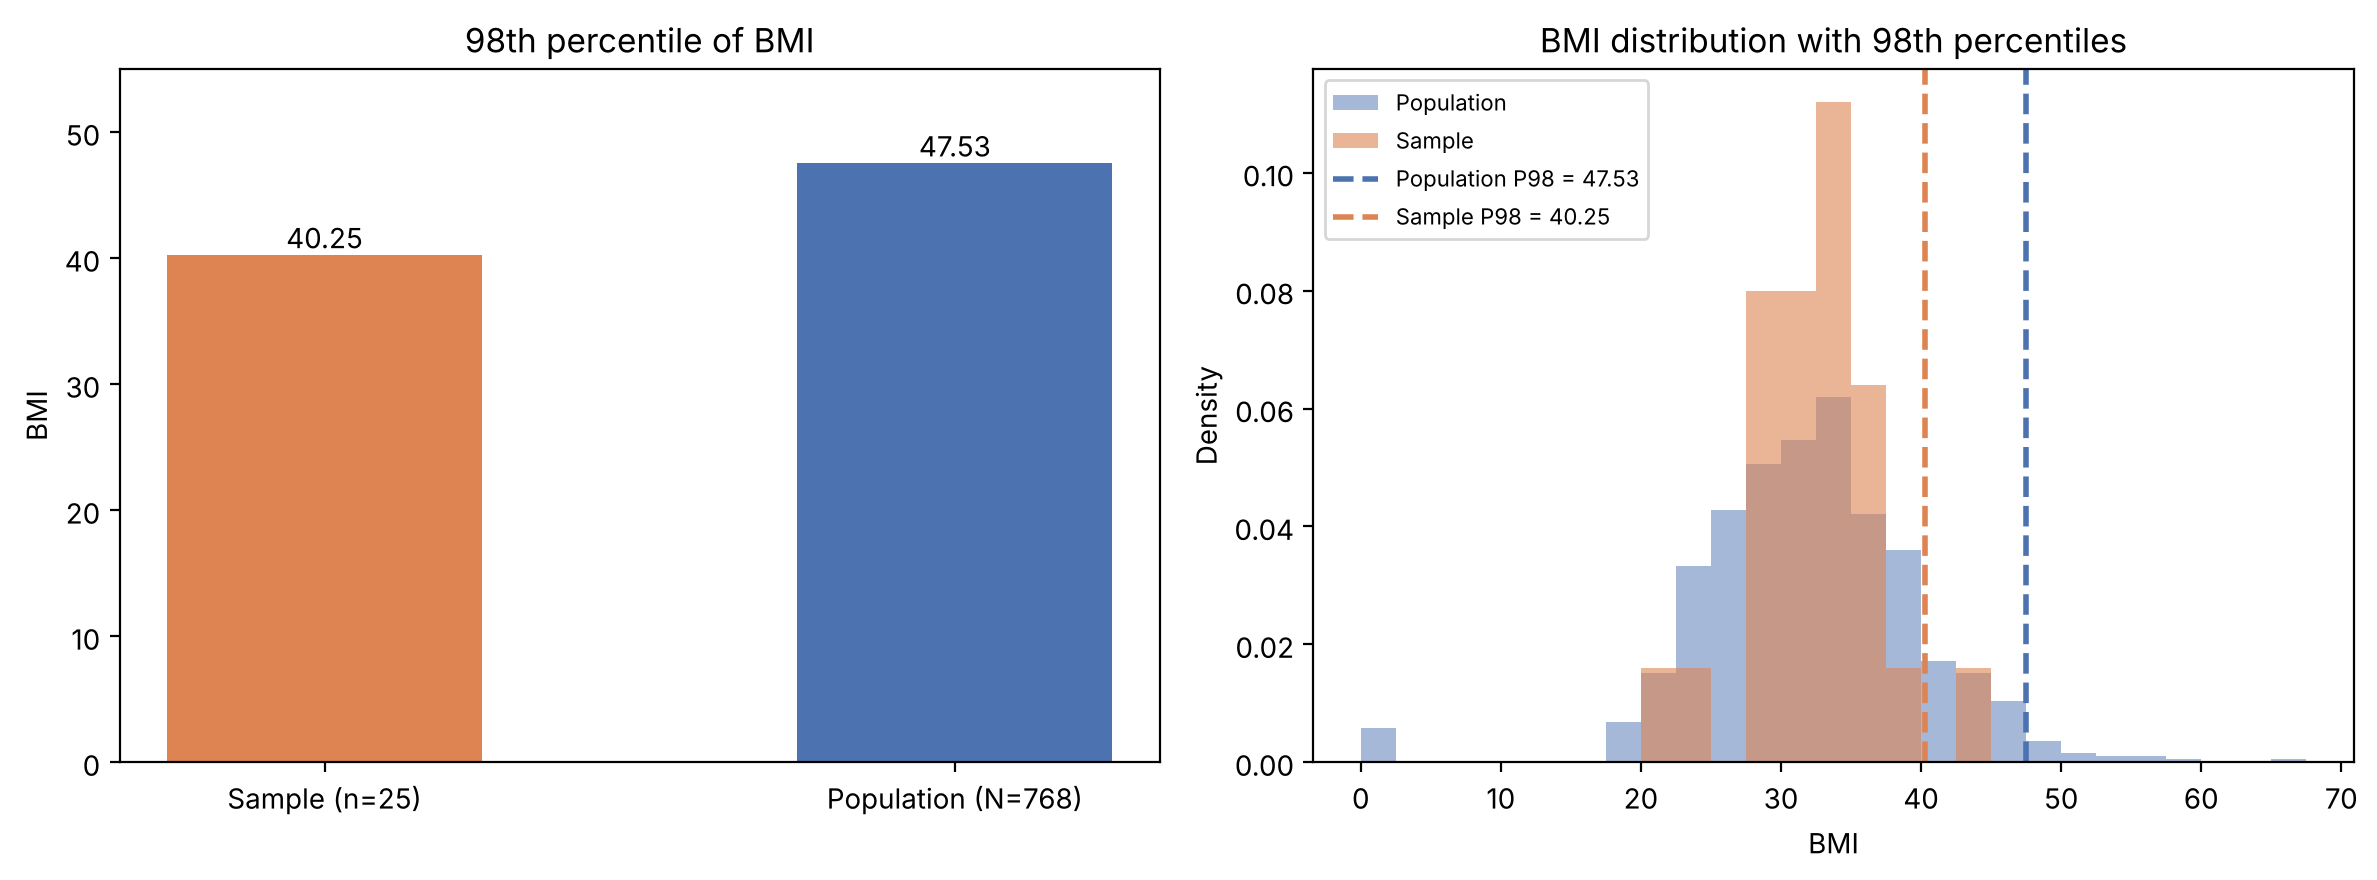

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
bars = ax.bar(bmi_cmp.index, bmi_cmp["98th percentile BMI"], color=[SAMPLE_COLOR, POP_COLOR], width=0.5)
ax.bar_label(bars, fmt="%.2f")
ax.set_ylabel("BMI")
ax.set_ylim(0, 55)
ax.set_title("98th percentile of BMI")

ax = axes[1]
bins = np.arange(0, 70, 2.5)
ax.hist(population["BMI"], bins=bins, density=True, alpha=0.5, color=POP_COLOR, label="Population")
ax.hist(sample25["BMI"], bins=bins, density=True, alpha=0.6, color=SAMPLE_COLOR, label="Sample")
ax.axvline(bmi_p98_pop, color=POP_COLOR, ls="--", lw=2, label=f"Population P98 = {bmi_p98_pop:.2f}")
ax.axvline(bmi_p98_sample, color=SAMPLE_COLOR, ls="--", lw=2, label=f"Sample P98 = {bmi_p98_sample:.2f}")
ax.set_xlabel("BMI"); ax.set_ylabel("Density")
ax.set_title("BMI distribution with 98th percentiles")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Observations (b)**

* The sample's 98th percentile BMI (**40.25**) is about **7.3 points (15%) lower** than the population's (**47.53**).
* The 98th percentile describes the extreme upper tail, so it has the same problem as the maximum in part (a). With n = 25, the "top 2%" comes down to interpolating between the one or two largest values, and the sample happened not to include the very high BMIs (50+) that exist in the population.
* Takeaway: **extreme percentiles need much larger samples** than the mean does to be estimated reliably.

## (c) Bootstrap: 500 samples of 150 BloodPressure values (with replacement)

For each of 500 iterations, draw 150 rows from the population **with replacement** (`replace=True`) and record the sample's **mean**, **standard deviation**, and **98th percentile** of `BloodPressure` (the same percentile as part (b)).
Then average each statistic across the 500 samples and compare it with the population value.

* The population standard deviation uses `ddof=0`, because the 768 rows *are* the population.
* Each bootstrap sample's standard deviation uses `ddof=1`, the usual sample estimator.

In [6]:
N_BOOT, N_SIZE, PCT = 500, 150, 98

boot_stats = []
for i in range(N_BOOT):
    bs = population.sample(n=N_SIZE, replace=True, random_state=SEED + i)["BloodPressure"]
    boot_stats.append({
        "mean": bs.mean(),
        "std": bs.std(ddof=1),
        f"p{PCT}": np.percentile(bs, PCT),
    })
boot = pd.DataFrame(boot_stats)
print(boot.shape)
boot.head()

(500, 3)


,mean,std,p98
0,71.160000,16.061158,100.00
1,70.480000,19.927627,100.16
2,67.986667,21.281743,96.04
3,67.040000,19.855478,92.04
4,70.133333,15.773424,92.16


In [7]:
bp = population["BloodPressure"]
print("BloodPressure readings of 0 in the population:", (bp == 0).sum())
pop_stats = pd.Series({
    "mean": bp.mean(),
    "std": bp.std(ddof=0),
    f"p{PCT}": np.percentile(bp, PCT),
})

summary = pd.DataFrame({
    "Population": pop_stats,
    "Bootstrap average (500 samples)": boot.mean(),
    "Bootstrap SD (spread of the 500 values)": boot.std(ddof=1),
})
summary["Difference (boot avg - pop)"] = summary["Bootstrap average (500 samples)"] - summary["Population"]
summary["% difference"] = summary["Difference (boot avg - pop)"] / summary["Population"] * 100
summary.index = ["Mean", "Standard deviation", f"{PCT}th percentile"]
summary.round(2)

BloodPressure readings of 0 in the population: 35


,Population,Bootstrap average (500 samples),Bootstrap SD (spread of the 500 values),Difference (boot avg - pop),% difference
Mean,69.11,69.18,1.61,0.07,0.10
Standard deviation,19.34,19.17,2.13,-0.17,-0.90
98th percentile,99.32,98.25,4.89,-1.07,-1.07


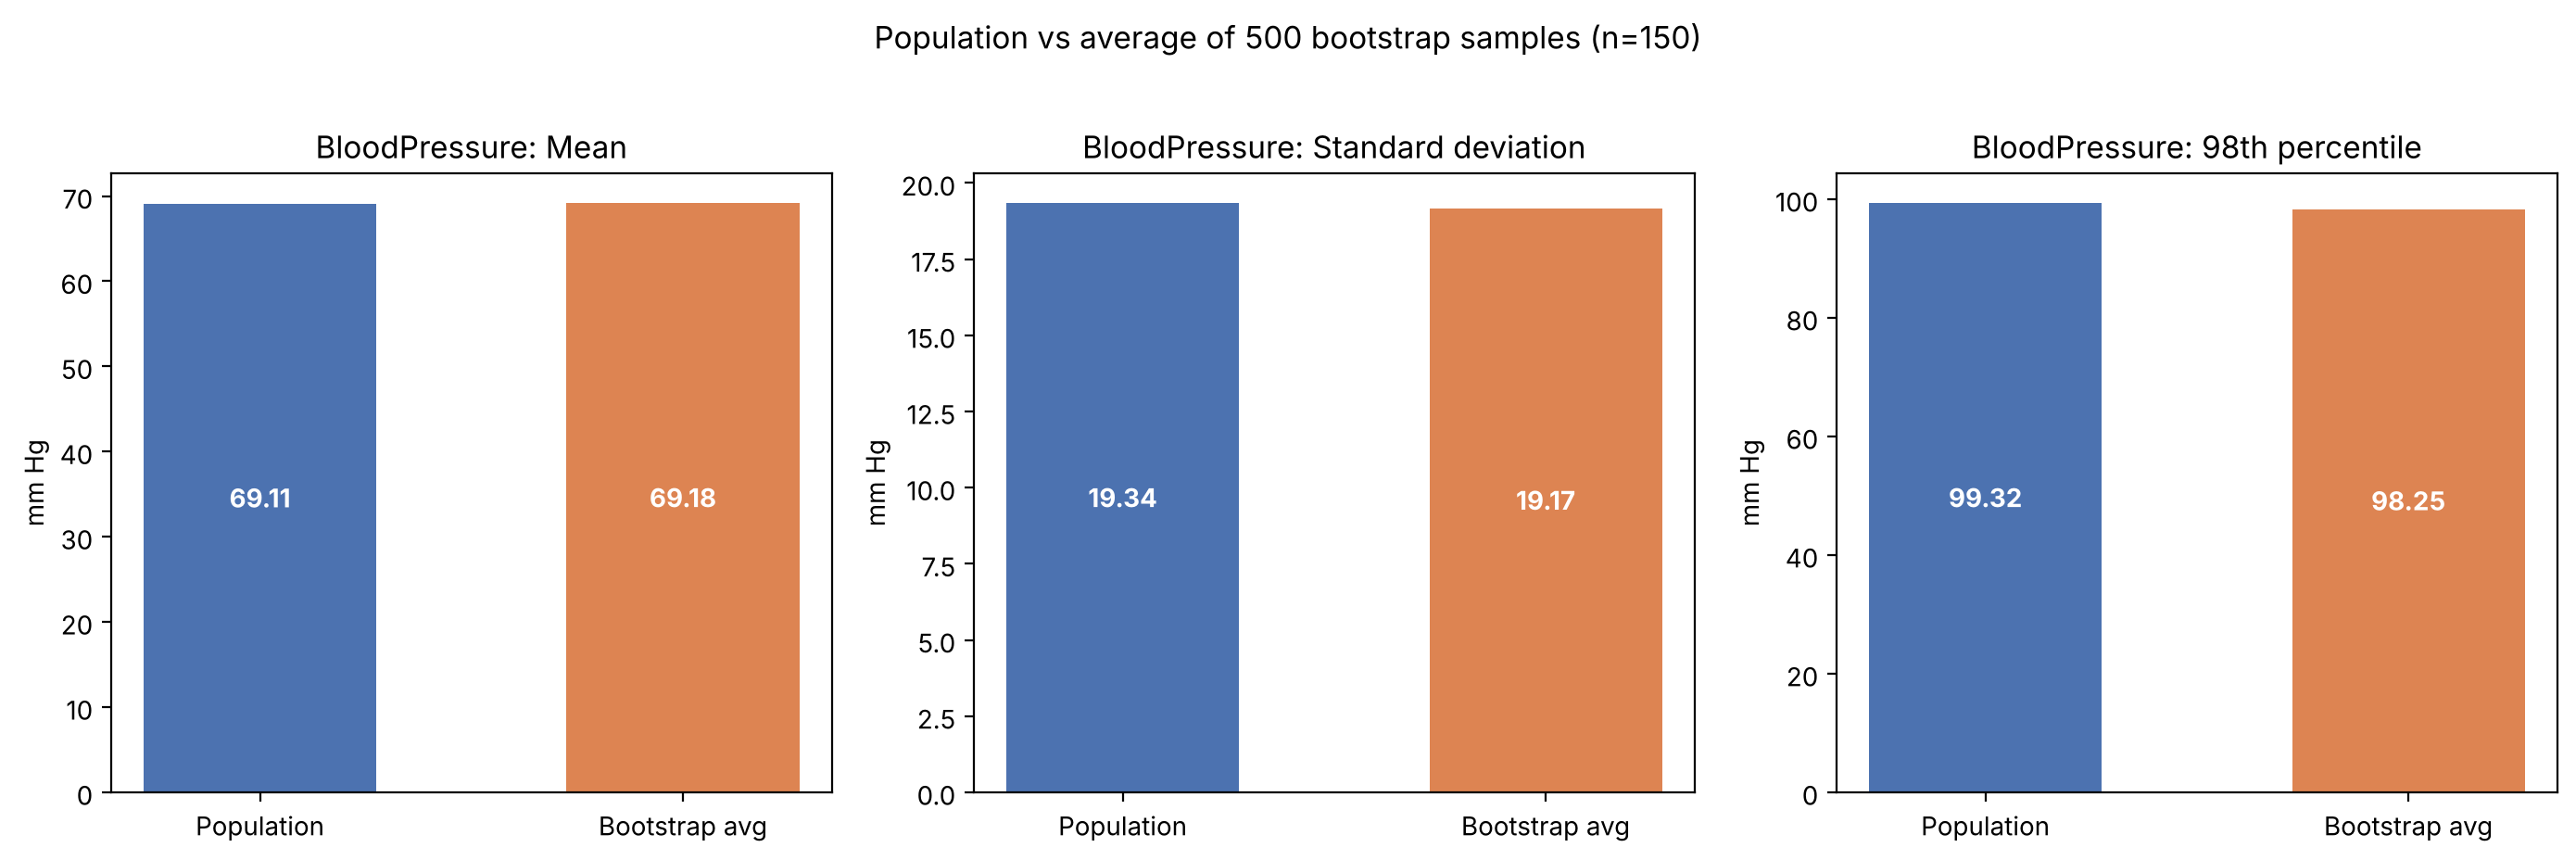

In [8]:
# Chart 1: population vs bootstrap average for each statistic (separate panels because scales differ).
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (label, row) in zip(axes, summary.iterrows()):
    vals = [row["Population"], row["Bootstrap average (500 samples)"]]  # spread is shown in the table and histograms
    bars = ax.bar(["Population", "Bootstrap avg"], vals, color=[POP_COLOR, SAMPLE_COLOR], width=0.55)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in vals], label_type="center", color="white", fontweight="bold")
    ax.set_title(f"BloodPressure: {label}")
    ax.set_ylabel("mm Hg")
fig.suptitle("Population vs average of 500 bootstrap samples (n=150)", y=1.02)
plt.tight_layout()
plt.show()

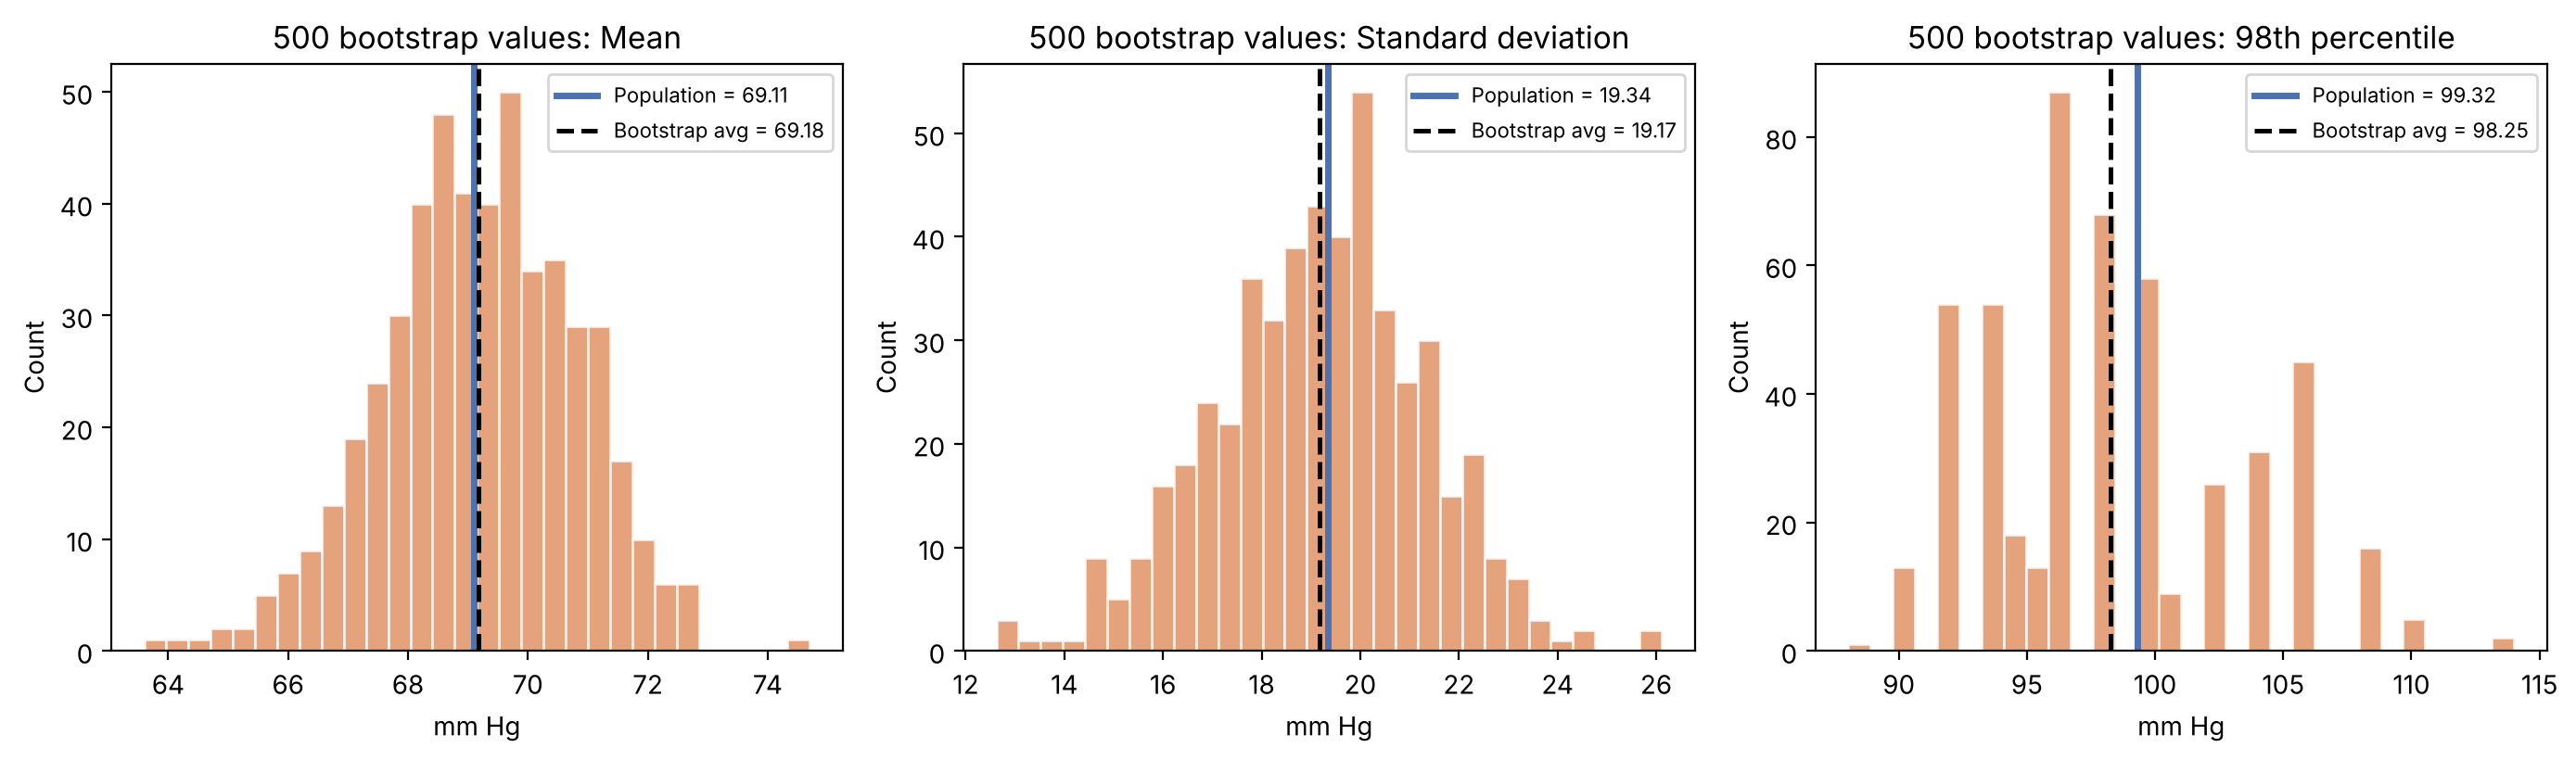

In [9]:
# Chart 2: sampling distributions of each statistic across the 500 bootstrap samples.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, col, label in zip(axes, boot.columns, summary.index):
    ax.hist(boot[col], bins=30, color=SAMPLE_COLOR, alpha=0.75, edgecolor="white")
    ax.axvline(pop_stats[col], color=POP_COLOR, lw=2.5, label=f"Population = {pop_stats[col]:.2f}")
    ax.axvline(boot[col].mean(), color="black", ls="--", lw=1.8, label=f"Bootstrap avg = {boot[col].mean():.2f}")
    ax.set_title(f"500 bootstrap values: {label}")
    ax.set_xlabel("mm Hg"); ax.set_ylabel("Count")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Findings

| Statistic | Population | Bootstrap average | Spread (SD of the 500 values) |
|---|---|---|---|
| Mean | 69.11 | 69.18 | 1.61 |
| Standard deviation | 19.34 | 19.17 | 2.13 |
| 98th percentile | 99.32 | 98.25 | 4.89 |

1. **Mean: almost no bias.** The average of the 500 bootstrap means (69.18) is within 0.1 mm Hg of the population mean (69.11). The sample mean is an unbiased estimator, and the histogram shows the 500 means forming a bell-shaped distribution centred on the true value, as the Central Limit Theorem predicts. It is also the most stable of the three statistics (spread 1.61).
2. **Standard deviation: close, slightly low.** The average bootstrap SD (19.17) is about 0.9% below the population SD (19.34). Even with `ddof=1`, the sample SD is slightly biased downward. The population contains 35 impossible readings of 0 mm Hg, and how many of these a sample happens to draw shifts its SD, which adds to its spread (2.13).
3. **98th percentile: most variable and biased low.** The bootstrap average (98.25) is about 1.1 mm Hg (1.1%) below the population value (99.32), and it varies the most from sample to sample (spread 4.89, about three times that of the mean). With 150 values, 2% is only the 3 largest readings, so this statistic is noisy and tends to underestimate the tail. This matches what parts (a) and (b) showed for the maximum and the 98th-percentile BMI.
4. **Overall:** with samples of 150, averaging over many bootstrap samples recovers the population **mean very accurately**, the **SD well**, and the **extreme percentile less reliably**. Statistics based on the centre of a distribution are estimated much more precisely than statistics based on its tails.